Heart Disease Prediction - Feature Engineering & Model Training


 Load cleaned data

In [2]:
import pandas as pd
df = pd.read_csv("heart_clean.csv")
print("Shape:", df.shape)
df.head()

Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Train / test split

In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="target")      # the 13 patient features (input)
y = df["target"]                   # 0 / 1 answer (output)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 242 | Test rows: 61


Feature preparation pipeline (scaling + encoding)

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
binary_cols = ["sex", "fbs", "exang"]
category_cols = ["cp", "restecg", "slope", "thal"]

preprocessor = ColumnTransformer([
    ("scale", StandardScaler(), numeric_cols),
    ("keep", "passthrough", binary_cols),
    ("onehot", OneHotEncoder(handle_unknown="ignore"), category_cols),
])

# quick check: fit on training data and look at the result size
print("Features after preprocessing:", preprocessor.fit_transform(X_train).shape)

Features after preprocessing: (242, 22)


Baseline models with 5-fold cross-validation

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "roc_auc"]

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
}

baseline = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    baseline[name] = {m: scores[f"test_{m}"].mean() for m in scoring}

pd.DataFrame(baseline).T.round(3)

,accuracy,precision,recall,roc_auc
Logistic Regression,0.839,0.877,0.766,0.907
Random Forest,0.806,0.822,0.747,0.888


Hyper-parameter tuning

In [6]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "model__n_estimators": [100, 300],
        "model__max_depth": [None, 4, 8],
        "model__min_samples_leaf": [1, 3],
    },
}

tuned = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    grid = GridSearchCV(pipe, param_grids[name], cv=cv, scoring=scoring,
                        refit="roc_auc", n_jobs=-1)
    grid.fit(X_train, y_train)
    i = grid.best_index_
    tuned[name] = {
        "best_params": grid.best_params_,
        **{m: grid.cv_results_[f"mean_test_{m}"][i] for m in scoring},
        "estimator": grid.best_estimator_,
    }
    print(f"{name}: best params = {grid.best_params_}")

Logistic Regression: best params = {'model__C': 1, 'model__class_weight': 'balanced'}
Random Forest: best params = {'model__max_depth': 4, 'model__min_samples_leaf': 3, 'model__n_estimators': 300}


Model comparison

In [7]:
rows = []
for name in models:
    rows.append({"Model": name, "Stage": "Baseline", **baseline[name]})
    rows.append({"Model": name, "Stage": "Tuned", **{m: tuned[name][m] for m in scoring}})
comparison = pd.DataFrame(rows).round(3)
comparison

,Model,Stage,accuracy,precision,recall,roc_auc
0,Logistic Regression,Baseline,0.839,0.877,0.766,0.907
1,Logistic Regression,Tuned,0.859,0.870,0.828,0.908
2,Random Forest,Baseline,0.806,0.822,0.747,0.888
3,Random Forest,Tuned,0.826,0.850,0.764,0.898


Evaluation of tuned models on the test set

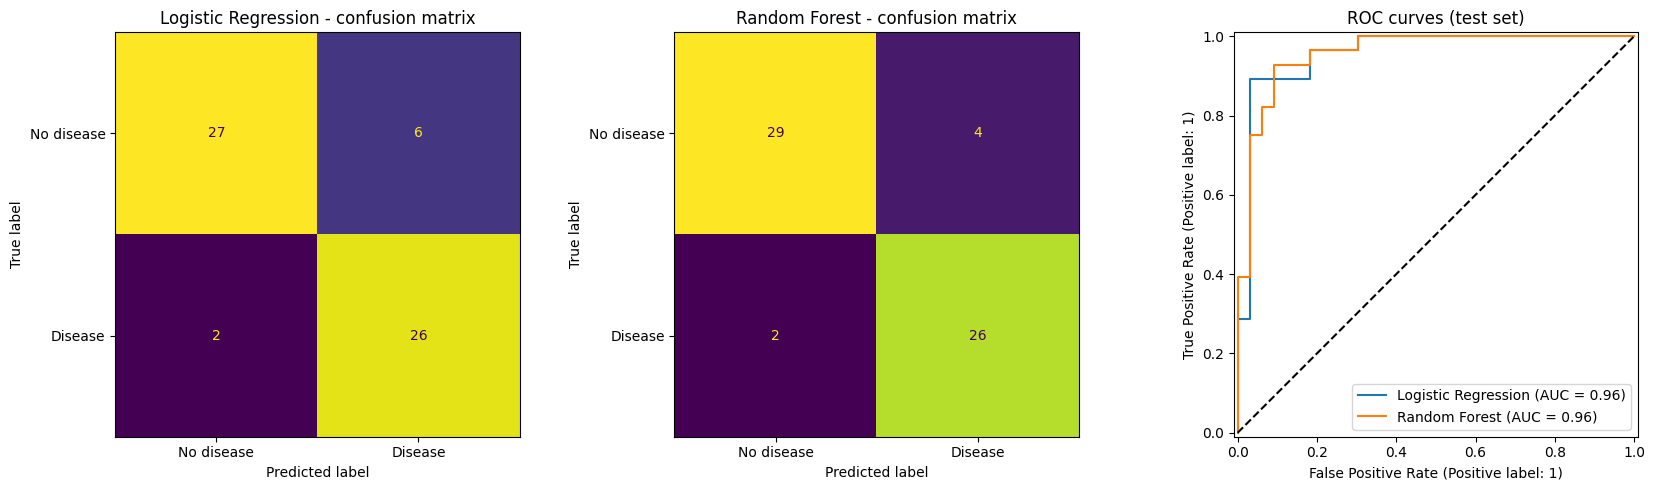

,Model,accuracy,precision,recall,roc_auc
0,Logistic Regression,0.869,0.812,0.929,0.958
1,Random Forest,0.902,0.867,0.929,0.958


In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)
import os
os.makedirs("figures", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
test_rows = []
for k, name in enumerate(models):
    est = tuned[name]["estimator"]
    pred = est.predict(X_test)
    prob = est.predict_proba(X_test)[:, 1]
    test_rows.append({"Model": name,
                      "accuracy": accuracy_score(y_test, pred),
                      "precision": precision_score(y_test, pred),
                      "recall": recall_score(y_test, pred),
                      "roc_auc": roc_auc_score(y_test, prob)})
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[k], colorbar=False,
                                            display_labels=["No disease", "Disease"])
    axes[k].set_title(f"{name} - confusion matrix")
    RocCurveDisplay.from_predictions(y_test, prob, ax=axes[2], name=name)
axes[2].plot([0, 1], [0, 1], "k--")
axes[2].set_title("ROC curves (test set)")
plt.tight_layout()
plt.savefig("figures/model_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(test_rows).round(3)

Model selection and tuning

Tuning process: Both models were tuned with GridSearchCV using stratified
5-fold cross-validation on the training set (242 patients), optimising ROC-AUC.
- Logistic Regression grid: C = [0.01, 0.1, 1, 10], class_weight = [None, balanced]
  -> best: C = 1, class_weight = balanced
- Random Forest grid: n_estimators = [100, 300], max_depth = [None, 4, 8],
  min_samples_leaf = [1, 3] -> best: n_estimators = 300, max_depth = 4, min_samples_leaf = 3

Results: Tuning improved both models (e.g. LR recall 0.766 -> 0.828).
Tuned Logistic Regression had the best cross-validated scores
(ROC-AUC 0.908, accuracy 0.859, recall 0.828) vs Random Forest (0.898, 0.826, 0.764).

Selected model: Logistic Regression. Selection is based on cross-validation,
not the test set. On the 61-patient test set, Random Forest had slightly higher
accuracy (0.902 vs 0.869), but this is a difference of only 2 false alarms; both
models found 26 of 28 sick patients (recall 0.929) and had the same ROC-AUC (0.958).
Logistic Regression is also simpler and interpretable, which suits a medical setting.

Save the selected model

In [9]:
import joblib
final_model = tuned["Logistic Regression"]["estimator"]   # pipeline: preprocessing + model
joblib.dump(final_model, "heart_model.joblib")
comparison.to_csv("model_comparison.csv", index=False)
loaded = joblib.load("heart_model.joblib")
print("Prediction:", loaded.predict(X_test.head(1)), "Probability:", loaded.predict_proba(X_test.head(1))[0, 1].round(3))

Prediction: [0] Probability: 0.24


In [12]:
!zip -r task2_outputs.zip figures heart_model.joblib model_comparison.csv
from google.colab import files
files.download("task2_outputs.zip")

updating: figures/ (stored 0%)
updating: figures/model_evaluation.png (deflated 17%)
updating: heart_model.joblib (deflated 52%)
updating: model_comparison.csv (deflated 39%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

TASK -03
Experiment tracking with MLflow

In [13]:
!pip install -q mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 96.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 88.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [25]:
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
mlflow.end_run()
mlflow.set_tracking_uri("sqlite:////content/heart_mlflow.db")
mlflow.set_experiment("heart-disease-classification")
print("MLflow ready:", mlflow.get_tracking_uri())

2026/10/19 15:49:24 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 15:49:24 INFO mlflow.store.db.utils: Updating database tables
2026/10/19 15:49:28 INFO mlflow.tracking.fluent: Experiment with name 'heart-disease-classification' does not exist. Creating a new experiment.


MLflow ready: sqlite:////content/heart_mlflow.db


Log all runs

In [27]:
for name, model in models.items():
    with mlflow.start_run(run_name=name):
        pipe = Pipeline([("prep", preprocessor), ("model", model)])
        grid = GridSearchCV(pipe, param_grids[name], cv=cv, scoring=scoring,
                            refit="roc_auc", n_jobs=-1)
        grid.fit(X_train, y_train)

        # 1) every combination tried -> one child run each
        for i, params in enumerate(grid.cv_results_["params"]):
            with mlflow.start_run(run_name=f"{name} - trial {i+1}", nested=True):
                mlflow.log_params({k.replace("model__", ""): str(v) for k, v in params.items()})
                for m in scoring:
                    mlflow.log_metric(f"cv_{m}", grid.cv_results_[f"mean_test_{m}"][i])

        # 2) best settings + cross-validation scores
        best = grid.best_estimator_
        mlflow.log_param("algorithm", name)
        mlflow.log_params({"best_" + k.replace("model__", ""): str(v) for k, v in grid.best_params_.items()})
        for m in scoring:
            mlflow.log_metric(f"cv_{m}", grid.cv_results_[f"mean_test_{m}"][grid.best_index_])

        # 3) test-set scores
        pred = best.predict(X_test)
        prob = best.predict_proba(X_test)[:, 1]
        mlflow.log_metrics({"test_accuracy": accuracy_score(y_test, pred),
                            "test_precision": precision_score(y_test, pred),
                            "test_recall": recall_score(y_test, pred),
                            "test_roc_auc": roc_auc_score(y_test, prob)})

        # 4) plots as artifacts
        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax[0], colorbar=False)
        RocCurveDisplay.from_predictions(y_test, prob, ax=ax[1])
        ax[0].set_title(f"{name} - confusion matrix"); ax[1].set_title("ROC curve")
        mlflow.log_figure(fig, "evaluation_plots.png")
        plt.close(fig)

        # 5) the model itself
        mlflow.sklearn.log_model(
            best,
            name="model",
            signature=infer_signature(X_train, best.predict(X_train)),
            input_example=X_train.head(3),
            skops_trusted_types=["sklearn.compose._column_transformer._RemainderColsList",
                                 "sklearn.tree._tree.Tree"],
        )
        mlflow.set_tag("selected_model", str(name == "Logistic Regression"))
        print(f"Logged {name}: {len(grid.cv_results_['params'])} trials + best model")

Logged Random Forest: 12 trials + best model


Note: Logistic Regression was logged first (8 trials + best model). Random Forest needed an extra trusted type (sklearn.tree._tree.Tree) for MLflow's secure skops smodel format, so it was logged in a second run (12 trials + best model).
Both runs are confirmed in the summary below and in the MLflow dashboard.

In [36]:
!pkill -f "mlflow ui"
import time; time.sleep(3)
get_ipython().system_raw(
    "mlflow ui --backend-store-uri sqlite:////content/heart_mlflow.db "
    "--port 5001 --allowed-hosts '*' --cors-allowed-origins '*' > mlflow_ui2.log 2>&1 &"
)
time.sleep(15)
!cat mlflow_ui2.log
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(5001)"))

Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled. Allowed hosts: *. CORS origins: *.
2026/10/19 15:59:28 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/10/19 15:59:28 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
2026/10/19 15:59:29 INFO:     Uvicorn running on http://127.0.0.1:5001 (Press CTRL+C to quit)
2026/10/19 15:59:29 INFO:     Started parent process [11917]
https://5001-m-s-kkb-usw1b2-3la7jcogjtmp9-b.us-west1-2.prod.colab.dev


In [38]:
runs = mlflow.search_runs(experiment_names=["heart-disease-classification"])
main = runs[runs["tags.mlflow.parentRunId"].isna()]
print("Total runs logged:", len(runs), "| Models:", len(main), "| Tuning trials:", len(runs) - len(main))
main[["tags.mlflow.runName", "metrics.cv_roc_auc", "metrics.cv_accuracy",
      "metrics.test_accuracy", "metrics.test_recall", "metrics.test_roc_auc"]].round(3)

Total runs logged: 22 | Models: 2 | Tuning trials: 20


,tags.mlflow.runName,metrics.cv_roc_auc,metrics.cv_accuracy,metrics.test_accuracy,metrics.test_recall,metrics.test_roc_auc
12,Random Forest,0.898,0.826,0.902,0.929,0.958
21,Logistic Regression,0.908,0.859,0.869,0.929,0.958


In [39]:
!zip -qr mlflow_records.zip heart_mlflow.db mlruns
from google.colab import files
files.download("mlflow_records.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MLflow (v3) was used for experiment tracking, with a SQLite backend store and local artifact storage. Each model is a parent run that logs its best hyper-parameters, mean 5-fold CV metrics (accuracy, precision, recall, ROC-AUC), test-set metrics, an evaluation plot (confusion matrix + ROC curve) and the trained pipeline with its input signature. Every hyper-parameter combination tried during GridSearchCV is logged as a nested child run (8 for Logistic Regression, 12 for Random Forest), giving 22 tracked runs in total.